Saving trajectory plots to G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\run_111227\kp_moseq_project\kappa_scan-1000000.0\trajectory_plots


Generating trajectory plots: 100%|██████| 28/28 [00:14<00:00,  1.99it/s]


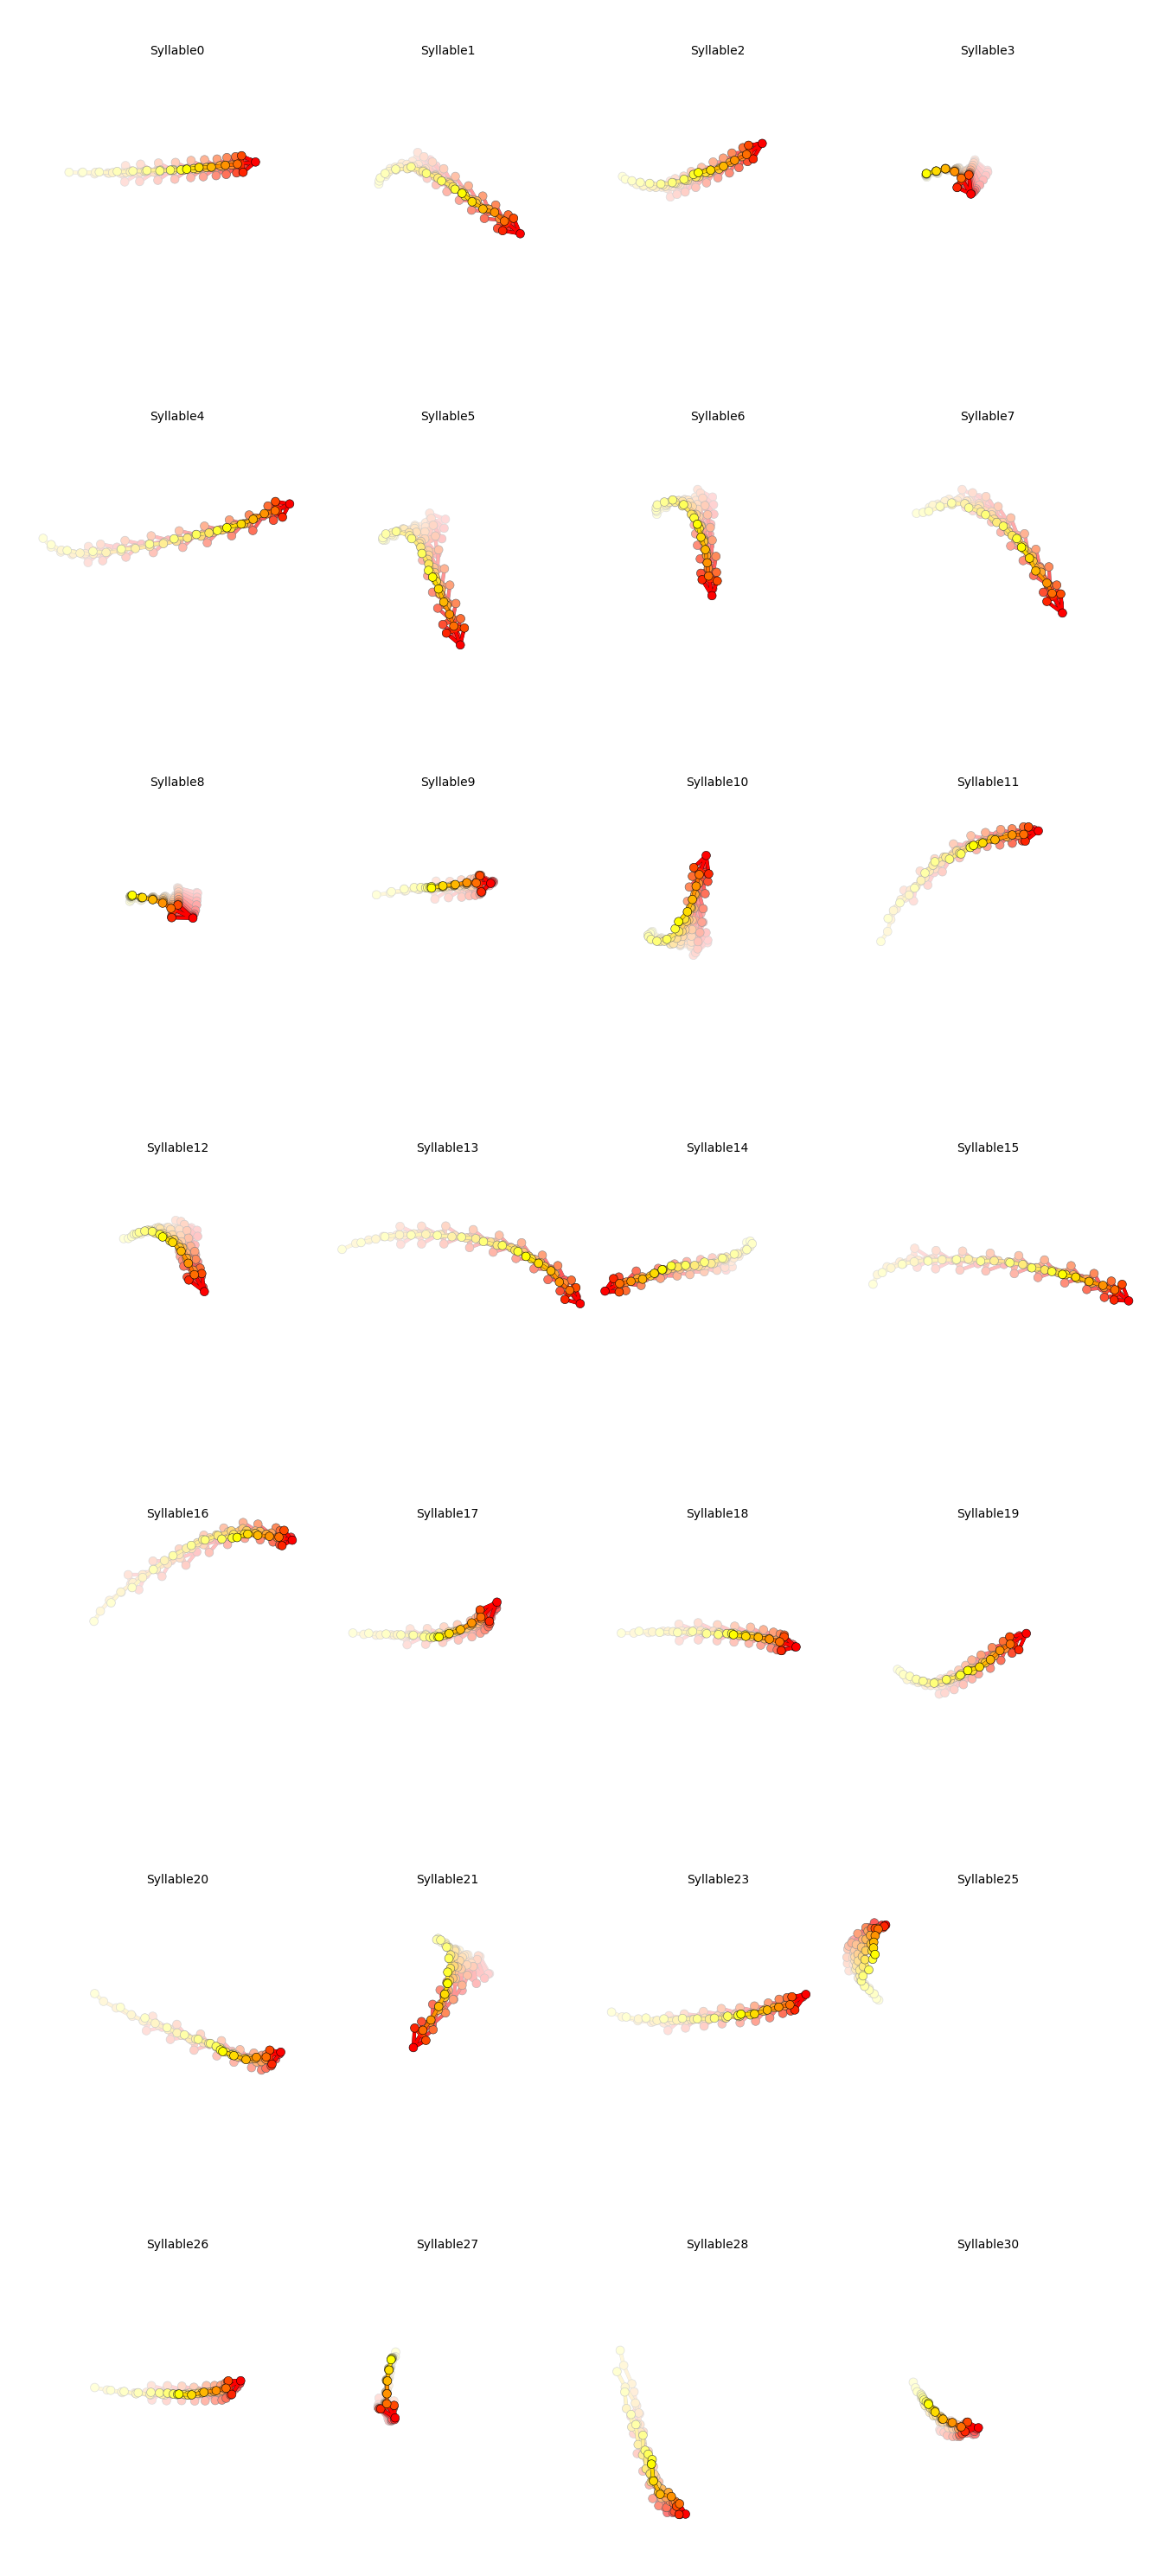

Trajectory plots generated for all recordings


In [28]:
# ==========================================================
# 16. Generate trajectory plots
# ==========================================================
with save_matplotlib_figures_as_png(dpi=300):
    kpms.generate_trajectory_plots(
        all_coordinates,  # Use all coordinates
        all_results,
        project_dir,
        model_name,
        **config,
    )

print("Trajectory plots generated for all recordings")

In [29]:
# ==========================================================
# 17. Match videos for grid movies
# ==========================================================
video_paths = build_video_paths_from_results(all_results, video_dir)

if len(video_paths) != len(all_results):
    print(f"\nWarning: Only {len(video_paths)}/{len(all_results)} recordings matched mp4 files.")

Matched: day4_260205_COC_AQP03DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered -> day4_260205_COC_AQP03DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered_p60_labeled.mp4
Matched: day5_260117_COC_WT01DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered -> day5_260117_COC_WT01DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered_p60_labeled.mp4
Matched: day5_260206_COC_WT02DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered -> day5_260206_COC_WT02DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered_p60_labeled.mp4
Matched: day5_260403_COC10_AQP04DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered -> day5_260403_COC10_AQP04DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered_p60_labeled.mp4
Matched: day3_260204_COC_WT02DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered -> day3_260204_COC_WT02DLC_Resnet50_260707_OFTJul7shuffle3_snapshot_best-80_filtered_p60_labeled.mp4
Matched: day1_260330_COC10_AQP04

In [30]:
# ==========================================================
# 18. Compute centroids and headings across all 60 recordings
# ==========================================================
centroids, headings = kpms.get_centroids_headings(
    all_coordinates,
    **config,
)

print("Centroids and headings computed")

Centroids and headings computed


In [31]:
# ==========================================================
# 19. Generate grid movies
# ==========================================================
# Filter to only recordings that have a verified mp4 video match
matched_results = {k: all_results[k] for k in video_paths.keys()}
matched_coords = {k: all_coordinates[k] for k in video_paths.keys()}
matched_centroids = {k: centroids[k] for k in video_paths.keys()}
matched_headings = {k: headings[k] for k in video_paths.keys()}

kpms.generate_grid_movies(
    matched_results,
    project_dir,
    model_name,
    video_paths=video_paths,
    coordinates=matched_coords,
    centroids=matched_centroids,
    headings=matched_headings,
    **config,
)

print("Grid movies generated")

Writing grid movies to G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\run_111227\kp_moseq_project\kappa_scan-1000000.0\grid_movies



Videos will be downscaled by a factor of 0.65 so that the grid movies
are under 1920 pixels. Use `max_video_size` to increase or decrease
this size limit.



Using window size of 496 pixels


Generating grid movies: 100%|███████████| 28/28 [02:21<00:00,  5.05s/it]

Grid movies generated


In [32]:
# ==========================================================
# 20. Final summary
# ==========================================================
print("\nkp-MoSeq full pipeline finished successfully!")
print("Run dir:", run_dir)
print("Project dir:", project_dir)
print("Model output dir:", model_output_dir)
print("Results CSV folder:", model_output_dir / "results_all_sessions")
print("Total analyzed recordings:", len(all_results))


kp-MoSeq full pipeline finished successfully!
Run dir: G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\run_111227
Project dir: G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\run_111227\kp_moseq_project
Model output dir: G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\run_111227\kp_moseq_project\kappa_scan-1000000.0
Results CSV folder: G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\run_111227\kp_moseq_project\kappa_scan-1000000.0\results_all_sessions
Total analyzed recordings: 60


In [33]:
# ==========================================================
# 21. Syllable Similarity Dendrogram
# ==========================================================
print("\nGenerating Syllable Similarity Dendrogram...")

# Calculate similarity dendrogram based on median syllable trajectories
fig = kpms.plot_similarity_dendrogram(
    all_coordinates,
    all_results,
    project_dir,
    model_name,
    **config,
)

dendrogram_path = model_output_dir / "syllable_similarity_dendrogram.png"
plt.savefig(dendrogram_path, dpi=300, bbox_inches="tight")
plt.close()
print(f"Dendrogram saved to: {dendrogram_path}")


Generating Syllable Similarity Dendrogram...
Saving dendrogram plot to G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\run_111227\kp_moseq_project\kappa_scan-1000000.0\similarity_dendrogram
Dendrogram saved to: G:\OFT_DLCv3_kpmoseq\kpmoseq_result\260924\run_111227\kp_moseq_project\kappa_scan-1000000.0\syllable_similarity_dendrogram.png
